# configuration & loadings

In [2]:
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.inspection import permutation_importance

plt.style.use("default")

In [3]:
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "gvns").exists():
    PROJECT_ROOT = Path(__file__).parent.parent.parent.parent if '__file__' in locals() else Path.cwd().parent.parent.parent

print(f"Project root: {PROJECT_ROOT}")

Project root: c:\Users\HP\Documents\GitHub\GVNS-implementation


In [4]:
DATA_PATH = PROJECT_ROOT / "gvns" / "ls_data" / "learning_dataset.csv"
MODEL_PATH = PROJECT_ROOT / "gvns" / "ml" / "models" / "rf_delta_regressor.pkl"
FEATURES_PATH = PROJECT_ROOT / "gvns" / "ml" / "models" / "rf_features.json"

# Load artifacts
df = pd.read_csv(DATA_PATH)
model = joblib.load(MODEL_PATH)

with open(FEATURES_PATH, "r") as f:
    feature_names = json.load(f)

print(f"Dataset shape: {df.shape}")
print(f"Number of features: {len(feature_names)}")

Dataset shape: (6684, 32)
Number of features: 30


# importance

In [5]:
# prepare X and y
df["log_delta"] = np.log1p(df["delta"].clip(lower=0))
y = df["log_delta"]

# Features
X = df[feature_names]

# Sanity check
assert X.shape[1] == len(feature_names)

## built-in RF importance

In [6]:
importances = pd.Series(
    model.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

importances.head(15)

F_before              0.213997
avg_delta_W           0.151245
F_after               0.116897
max_delta_W           0.092791
penS_ratio            0.083755
ls_call_id            0.047483
elapsed               0.043274
time_elapsed_ratio    0.041486
time_left_ratio       0.037981
PV                    0.034378
improv_rate_W         0.026461
ls_fail_ratio_W       0.026353
pen_ratio             0.024524
penT_ratio            0.017805
strategy              0.009859
dtype: float64

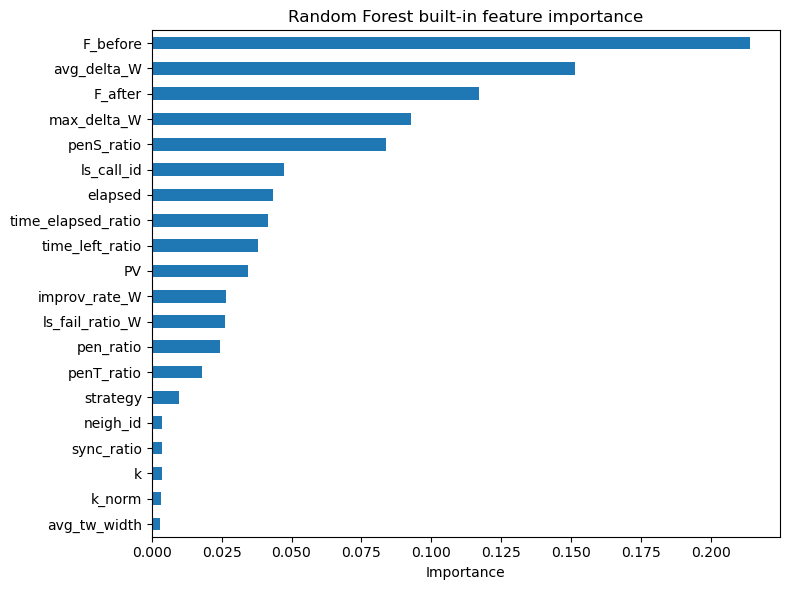

In [7]:
top_n = 20

plt.figure(figsize=(8, 6))
importances.head(top_n).iloc[::-1].plot(kind="barh")
plt.title("Random Forest built-in feature importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## permutation importance 

In [ ]:
perm = permutation_importance(
    model,
    X,
    y,
    n_repeats=10,
    random_state=42,
    n_jobs=-1,
    scoring="neg_mean_squared_error"
)

perm_importance = pd.Series(
    perm.importances_mean,
    index=feature_names
).sort_values(ascending=False)

perm_importance

F_before              1.320811
avg_delta_W           0.623147
max_delta_W           0.305136
elapsed               0.270201
F_after               0.209920
ls_call_id            0.139544
penS_ratio            0.129760
ls_fail_ratio_W       0.100133
time_left_ratio       0.094555
improv_rate_W         0.093817
time_elapsed_ratio    0.091995
pen_ratio             0.086431
penT_ratio            0.061528
strategy              0.044219
PV                    0.039856
k                     0.028972
k_norm                0.027648
neigh_id              0.024054
iter_gvns             0.017378
gvns_iter             0.011914
avg_tw_width          0.010132
sync_ratio            0.009979
tw_tightness          0.008623
horizon               0.008485
min_tw_width          0.006544
early_tw_ratio        0.004637
late_tw_ratio         0.002787
stagnation_ls         0.000000
n_customers           0.000000
n_vehicles            0.000000
dtype: float64

In [13]:
perm_df = perm_importance.reset_index()
perm_df.columns = ["feature", "importance"]
perm_df


,feature,importance
0,F_before,1.320811
1,avg_delta_W,0.623147
2,max_delta_W,0.305136
3,elapsed,0.270201
4,F_after,0.209920
5,ls_call_id,0.139544
6,penS_ratio,0.129760
7,ls_fail_ratio_W,0.100133
8,time_left_ratio,0.094555
9,improv_rate_W,0.093817


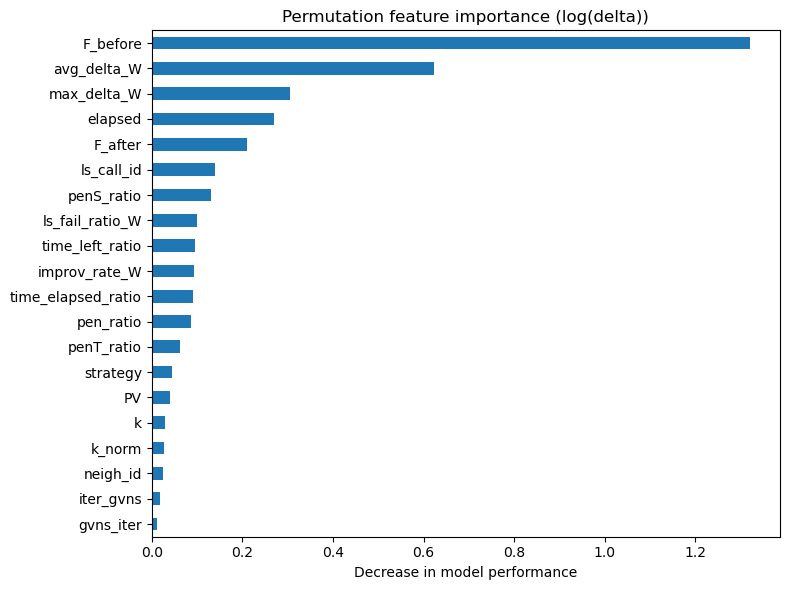

In [13]:
top_n = 20

plt.figure(figsize=(8, 6))
perm_importance.head(top_n).iloc[::-1].plot(kind="barh")
plt.title("Permutation feature importance (log(delta))")
plt.xlabel("Decrease in model performance")
plt.tight_layout()
plt.show()

### comparison 

In [ ]:
comparison = pd.DataFrame({
    "rf_importance": importances,
    "perm_importance": perm_importance
}).sort_values("perm_importance", ascending=False)

comparison

,rf_importance,perm_importance
F_before,0.213997,1.320811
avg_delta_W,0.151245,0.623147
max_delta_W,0.092791,0.305136
elapsed,0.043274,0.270201
F_after,0.116897,0.209920
ls_call_id,0.047483,0.139544
penS_ratio,0.083755,0.129760
ls_fail_ratio_W,0.026353,0.100133
time_left_ratio,0.037981,0.094555
improv_rate_W,0.026461,0.093817


## grouped importance 
its more "reasearch grade" 

In [14]:
FEATURE_GROUPS = {
    "search_dynamics": [
        "improv_rate_W",
        "avg_delta_W",
        "max_delta_W",
        "ls_fail_ratio_W",
        "time_left_ratio",
        "time_elapsed_ratio",
    ],
    "strategy_control": [
        "strategy",
        "k",
        "k_norm",
        "neigh_id",
    ],
    "instance_structure": [
        "tw_tightness",
        "avg_tw_width",
        "min_tw_width",
        "early_tw_ratio",
        "late_tw_ratio",
        "n_customers",
        "n_vehicles",
        "horizon",
        "sync_ratio",
    ],
    "penalties": [
        "pen_ratio",
        "penT_ratio",
        "penS_ratio",
    ],
}

group_importance = {}

for group, feats in FEATURE_GROUPS.items():
    feats = [f for f in feats if f in perm_importance]
    group_importance[group] = perm_importance[feats].sum()

grp_importance = pd.Series(group_importance).sort_values(ascending=False)
grp_importance

search_dynamics       1.308784
penalties             0.277719
strategy_control      0.124893
instance_structure    0.051188
dtype: float64

In [15]:
grp_df = grp_importance.reset_index()
grp_df.columns = ["groupe", "importance"]
grp_df

,groupe,importance
0,search_dynamics,1.308784
1,penalties,0.277719
2,strategy_control,0.124893
3,instance_structure,0.051188
